# CNN Classification of Emotions

## Imports

In [126]:
import dl_lib
import json
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.utils.data as data
import torch.optim as optim
from torchvision.transforms import v2
from torchvision.datasets import ImageFolder

from sklearn.metrics import f1_score, ConfusionMatrixDisplay
import pathlib

from collections import Counter

### Set Random Seed for Reproducibility

In [ ]:
RANDOM_SEED = 25353
torch.manual_seed(RANDOM_SEED)

Check if other backends are available, otherwise fall back on cpu

In [128]:
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

CNN Model Architecture

In [ ]:
class CNN(nn.Module):
    def __init__(self, input_dim, hidden_dim=16):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(input_dim, hidden_dim, kernel_size=(2, 2)),
            nn.BatchNorm2d(hidden_dim),
            nn.GELU(),
            nn.MaxPool2d(2, 2),
            nn.Conv2d(hidden_dim, hidden_dim * 2, kernel_size=(2, 2)),
            nn.BatchNorm2d(hidden_dim * 2),
            nn.GELU(),
            nn.MaxPool2d(2, 2),
            nn.Conv2d(hidden_dim * 2, hidden_dim * 4, kernel_size=(2, 2)),
            nn.BatchNorm2d(hidden_dim * 4),
            nn.GELU(),
            nn.MaxPool2d(2, 2),
            nn.Flatten(),
            nn.LazyLinear(128),
            nn.ReLU(),
            nn.Linear(128, 7),
        )

    def forward(self, x):
        return self.network(x)

Load Data 

In [130]:
train_data_path = pathlib.Path("data/train")
test_data_path = pathlib.Path("data/test")

train_data = ImageFolder(train_data_path)

Determine Class Balance

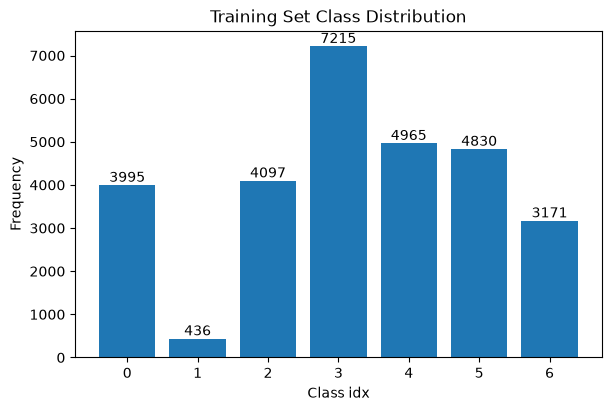

In [131]:
freqs = Counter(train_data.targets)
fig, ax = plt.subplots(layout="constrained", figsize=(6, 4))
bars = ax.bar(freqs.keys(), freqs.values())
ax.bar_label(bars)
ax.set_xlabel("Class idx")
ax.set_ylabel("Frequency")
ax.set_title("Training Set Class Distribution");

In [132]:
def calc_class_weights(train_set, frequencies):
    total = len(train_set)
    return total / (7 * torch.tensor(list(frequencies.values()), dtype=torch.int32))


class_weights = calc_class_weights(train_data, freqs)

In [133]:
with open("idx_to_class.json", "w") as file:
    json.dump({value: key for key, value in train_data.class_to_idx.items()}, file)

In [134]:
def calc_mean_std(dataloader):
    channels_sum, channels_squared_sum, num_batches = 0, 0, 0
    for data, _ in dataloader:
        # Average across Batch (0), Height (2), and Width (3)
        channels_sum += torch.mean(data, dim=(0, 2, 3))
        channels_squared_sum += torch.mean(data**2, dim=(0, 2, 3))
        num_batches += 1

    mean = channels_sum / num_batches
    std = torch.sqrt((channels_squared_sum / num_batches - mean**2))

    return mean, std

In [ ]:
temp_train_loader = data.DataLoader(train_data, batch_size=64)
temp_train_loader.dataset.transform = v2.ToTensor()
mean, std = calc_mean_std(temp_train_loader)
del temp_train_loader

Data Augmentation Transforms.

mean and std are calculated on the train set, and then applied to all for normalization.

In [136]:
transforms = v2.Compose(
    [
        v2.ToImage(),
        v2.RandomRotation(degrees=(-45, 45)),
        v2.RandomHorizontalFlip(),
        v2.RandomVerticalFlip(),
        v2.RandomPerspective(),
        v2.GaussianBlur((3, 3)),
        v2.ToDtype(torch.float32, scale=True),
        v2.Normalize(mean=mean, std=std),
    ]
)

test_transforms = v2.Compose(
    [
        v2.ToImage(),
        v2.ToDtype(torch.float32, scale=True),
        v2.Normalize(mean=mean, std=std),
    ]
)

In [137]:
test_data = ImageFolder(test_data_path, transform=test_transforms)
val_data, test_data = data.random_split(test_data, [0.6, 0.4])

In [138]:
train_loader = data.DataLoader(train_data, shuffle=True, batch_size=32)
train_loader.dataset.transform = transforms

val_loader = data.DataLoader(val_data, batch_size=32)
test_loader = data.DataLoader(test_data, batch_size=32)

In [139]:
def get_f1(model, validation_loader, device="cpu"):
    predictions = []
    actual = []
    model.eval()
    model.to(device)
    with torch.no_grad():
        for X, y in validation_loader:
            X = X.to(device)
            prediction = torch.argmax(model(X), dim=1)
            predictions.extend(prediction.cpu().numpy())
            actual.extend(y.cpu().numpy())

    return f1_score(actual, predictions, average="macro"), (actual, predictions)

Model without accounting for class imbalance

In [ ]:
model = CNN(input_dim=3)
optimizer = optim.AdamW(model.parameters())
criterion = nn.CrossEntropyLoss()


trained_CNN, losses = dl_lib.train_model(
    model,
    criterion,
    optimizer,
    train_loader,
    val_loader,
    epochs=25,
    patience=3,
    device=device,
)

In [141]:
unbalanced_f1, unbalanced_predictions = get_f1(trained_CNN, test_loader, device=device)

The minority class is never predicted.

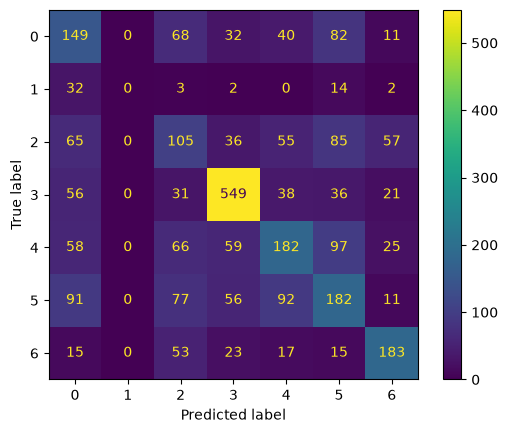

In [142]:
ConfusionMatrixDisplay.from_predictions(
    unbalanced_predictions[0], unbalanced_predictions[1]
)

In [143]:
def plot_loss(training, validation, f1score=None):
    fig, ax = plt.subplots(figsize=(16, 16), layout="constrained")
    ax.plot(training, label="Training Loss")
    ax.plot(validation, label="Validation Loss")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    if f1score is not None:
        ax.set_title(f"Model Loss | Macro F1 {f1score:.3f}")
    else:
        ax.set_title(f"Model Loss")

    ax.legend()

In [144]:
def save_model(model, path: pathlib.Path, filename: str = "model_weights"):
    torch.save(model.state_dict(), path.joinpath(f"{filename}.pth"))

In [154]:
save_model(trained_CNN, pathlib.Path("."), "imbalanced_with_activation")

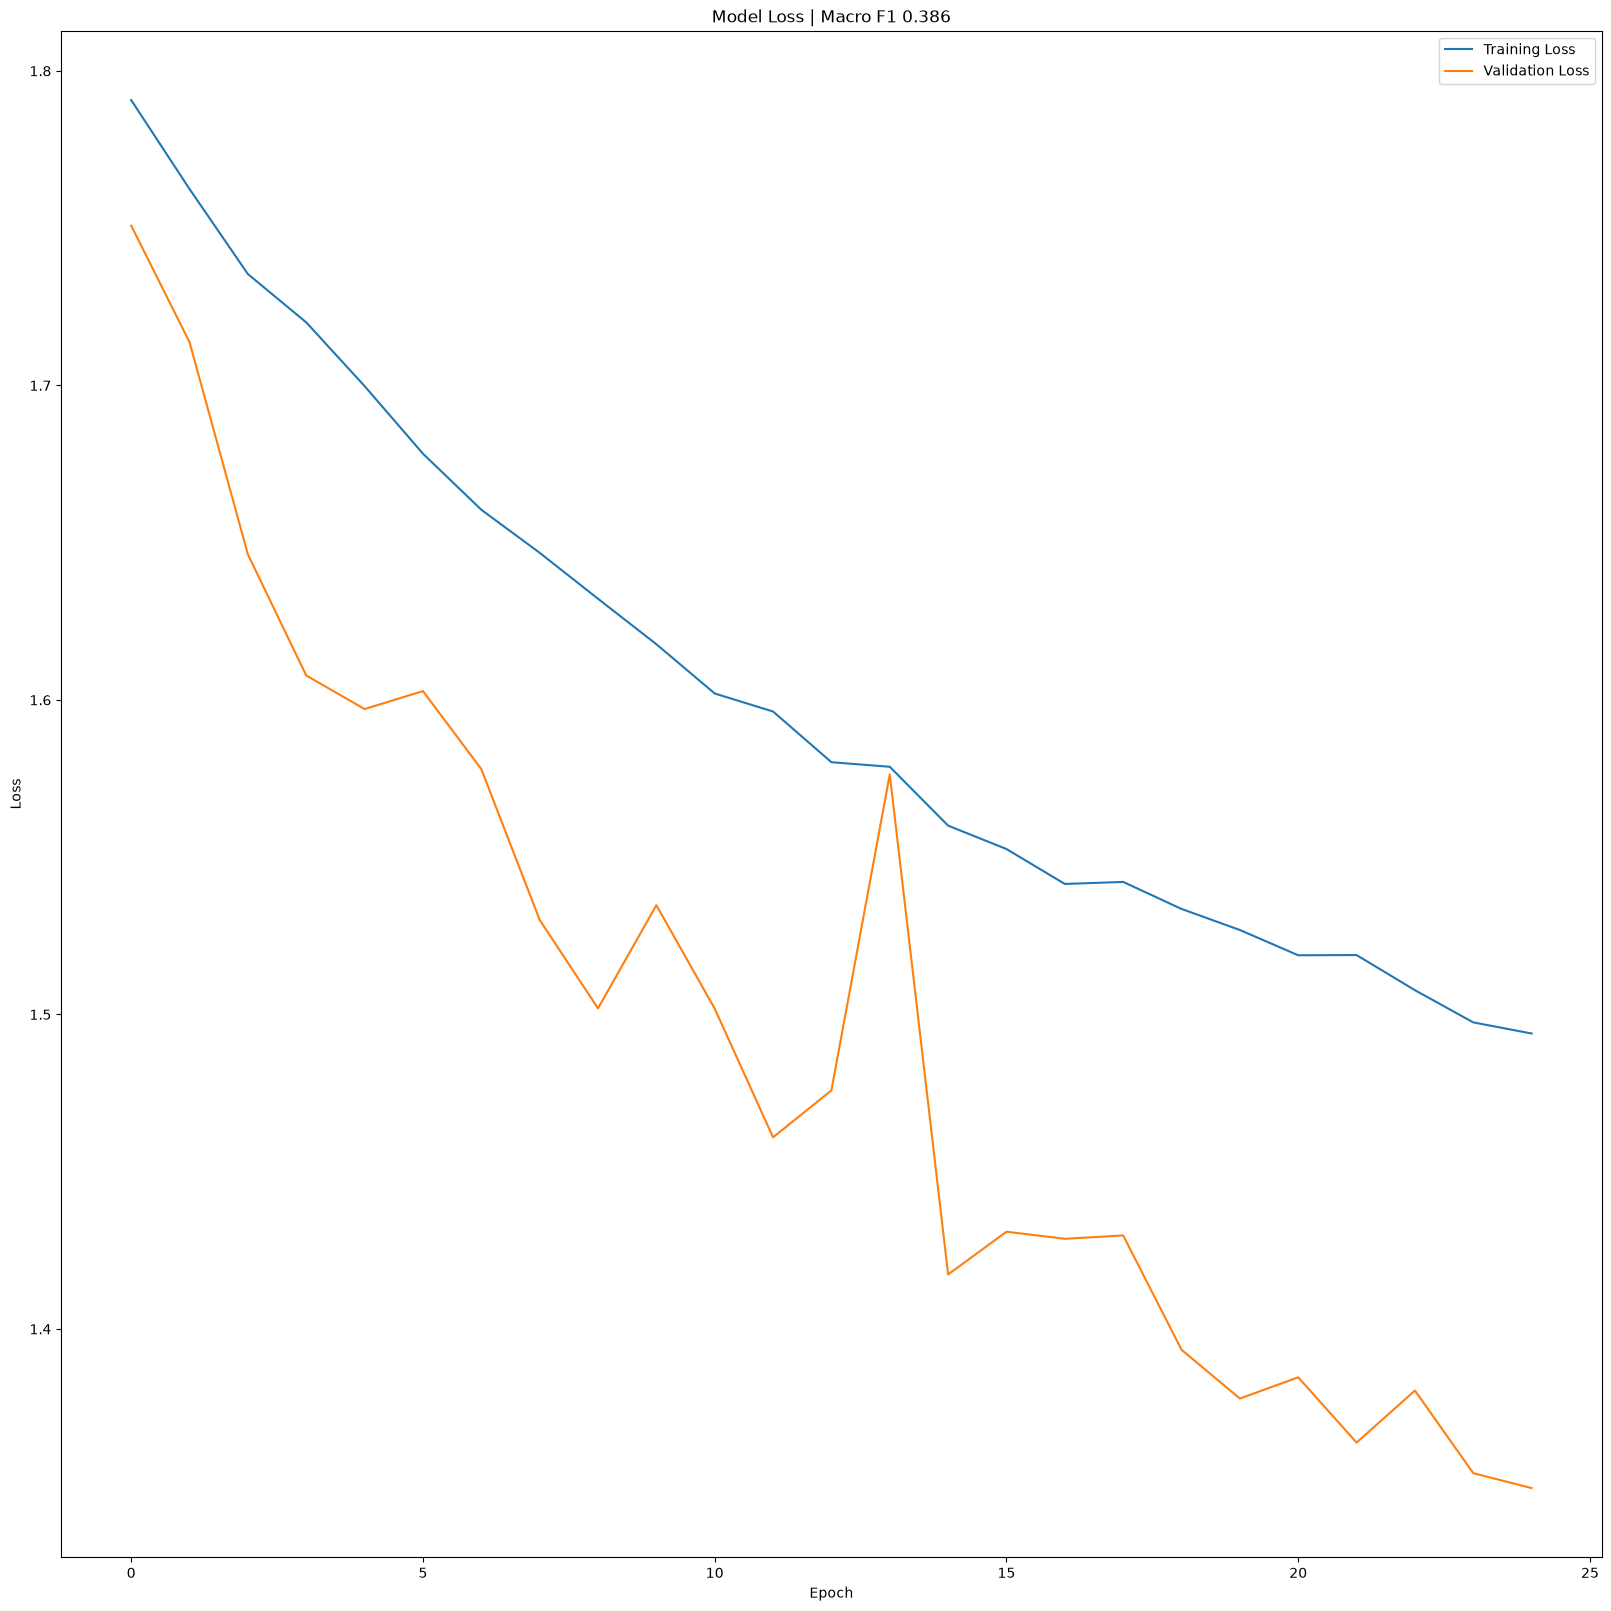

In [146]:
plot_loss(losses[0], losses[1], f1score=unbalanced_f1)

Add weighting to loss function to account for the class imbalance

In [ ]:
# Weighted Model
model = CNN(input_dim=3)
optimizer = optim.AdamW(model.parameters())
criterion = nn.CrossEntropyLoss(weight=class_weights)


trained_CNN_weighted, losses_weighted = dl_lib.train_model(
    model,
    criterion,
    optimizer,
    train_loader,
    val_loader,
    epochs=25,
    patience=3,
    device=device,
)

In [ ]:
balanced_f1, balanced_predictions = get_f1(trained_CNN_weighted, test_loader, device)

Model now predicts the minority class

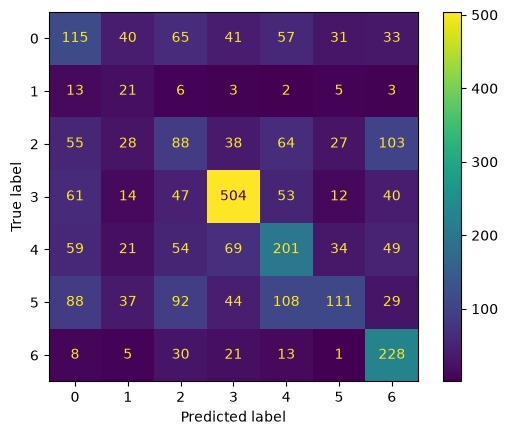

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    balanced_predictions[0], balanced_predictions[1]
)

In [153]:
save_model(trained_CNN_weighted, pathlib.Path("."), "balanced_with_activation")

As can be seen, F1 does not meaningfully change between models, however the model which accounts for the class imbalance is better --> as it is able to predict it

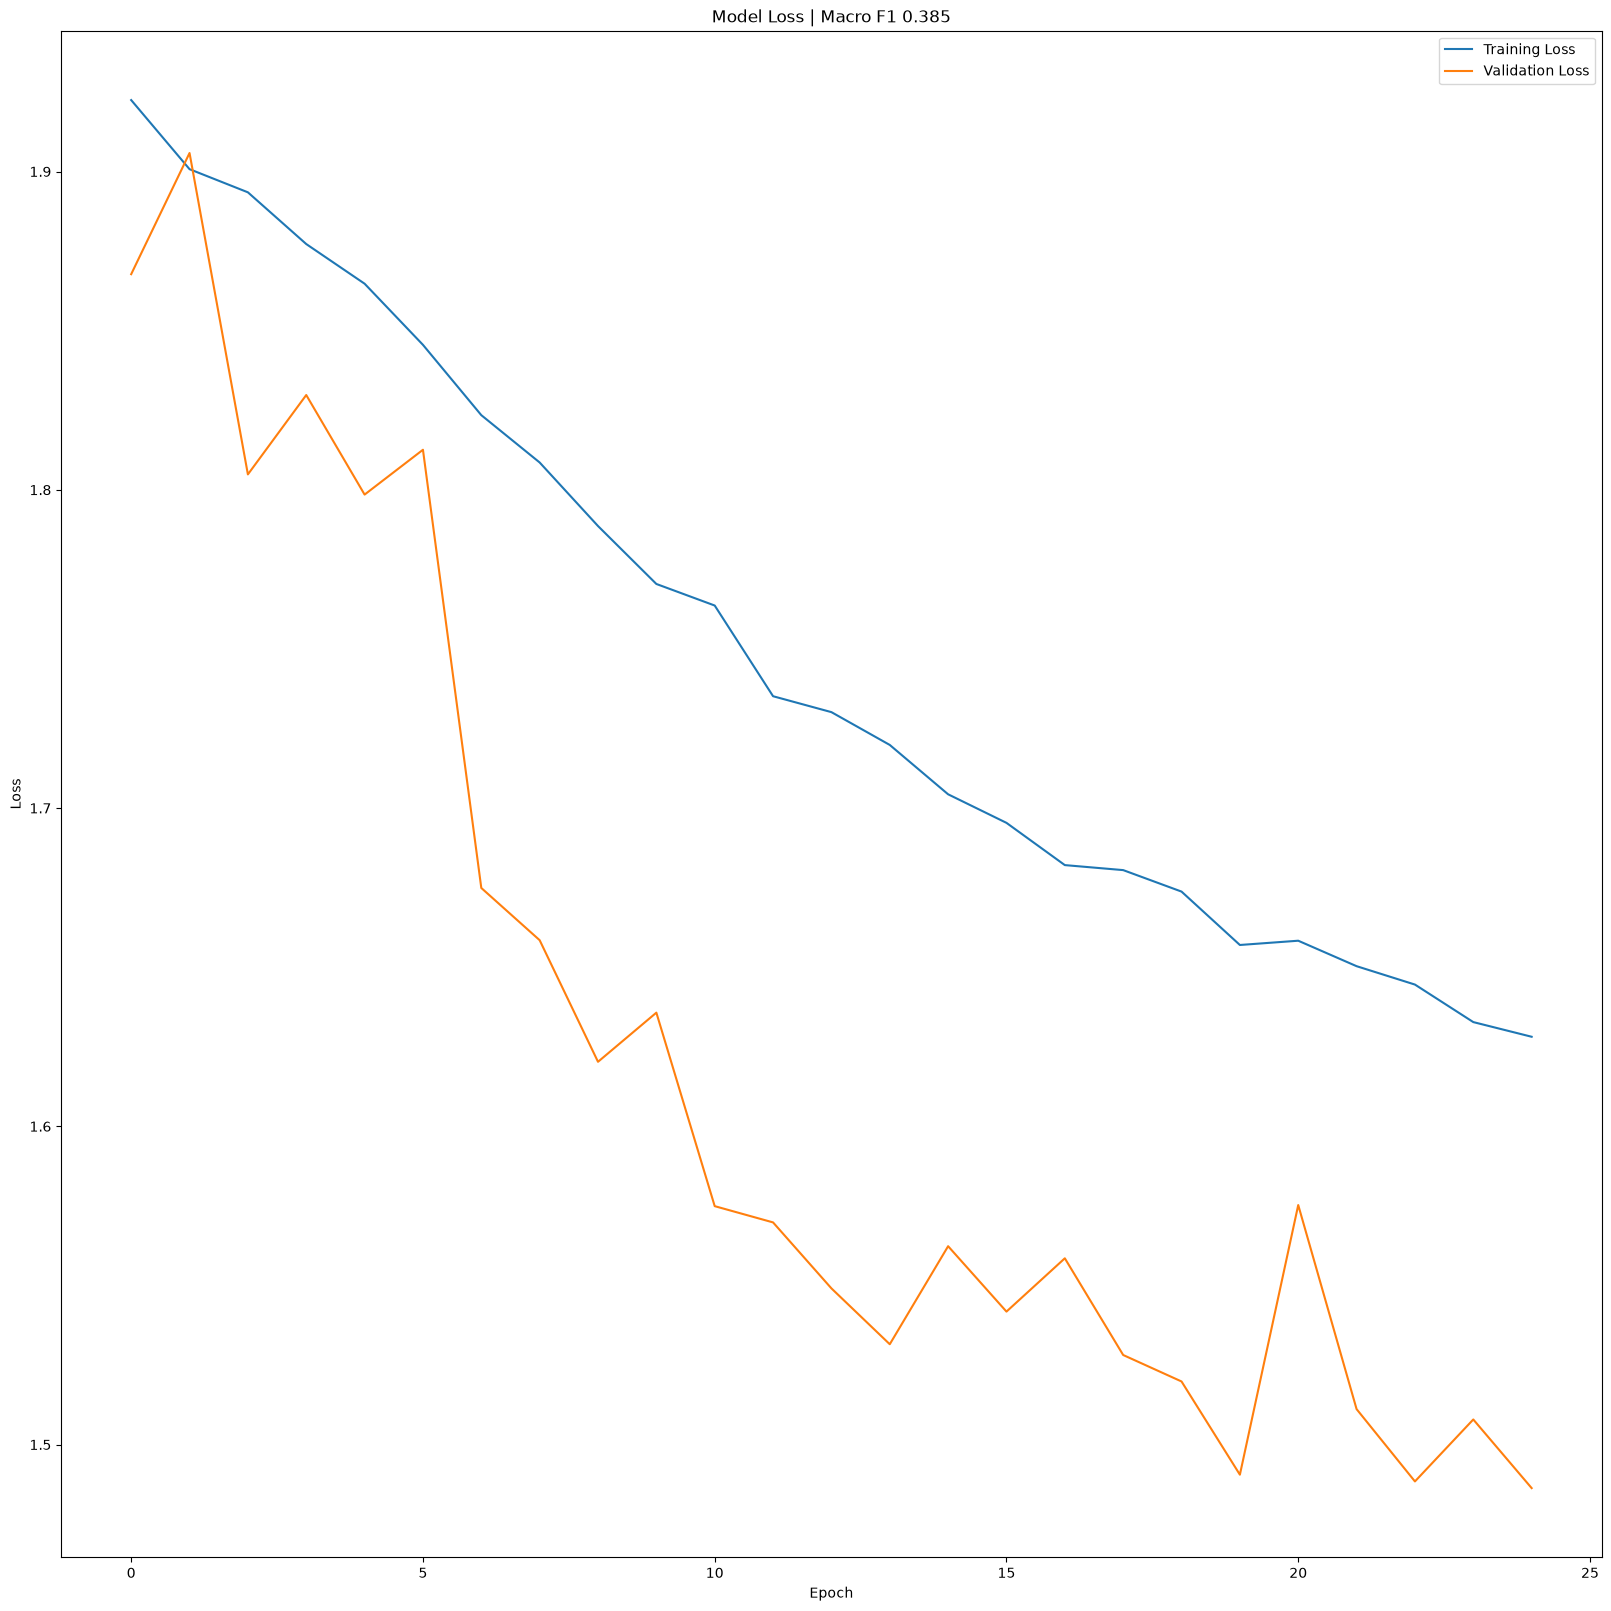

In [151]:
plot_loss(losses_weighted[0], losses_weighted[1], balanced_f1)

In [152]:
with open("mean_std.json", "w") as file:
    json.dump({"mean": mean.tolist(), "std": std.tolist()}, file)

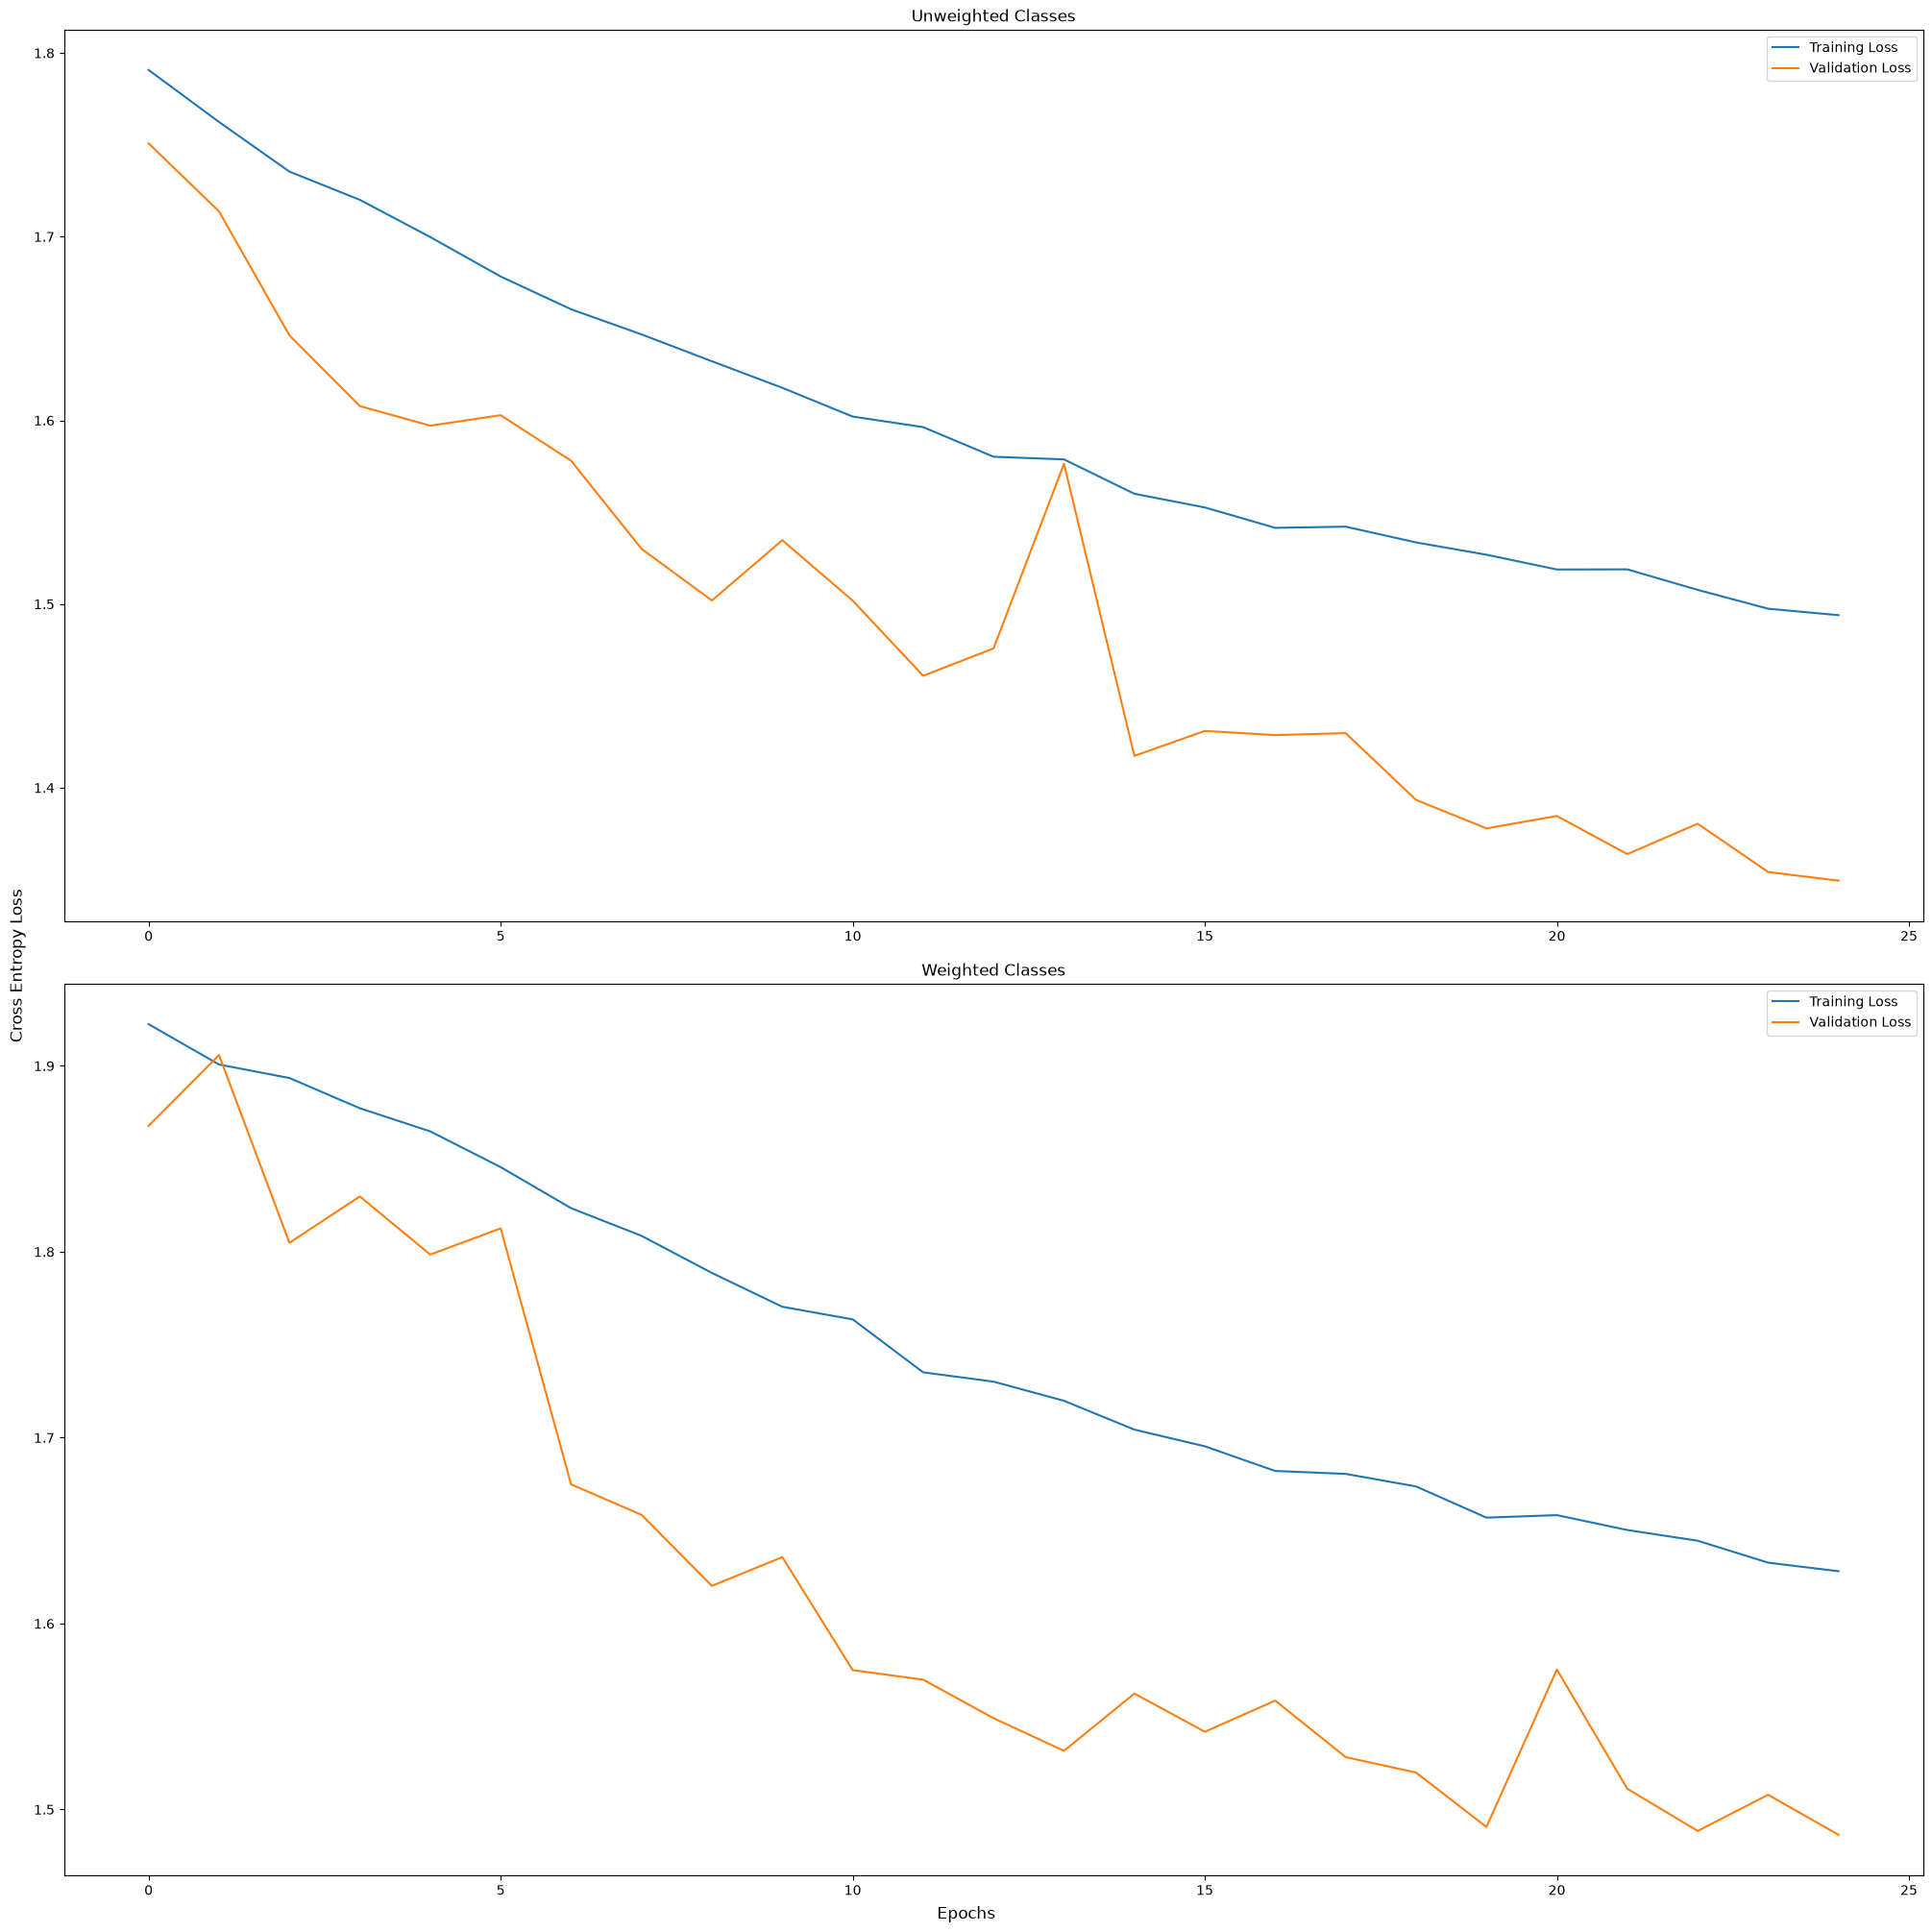

In [163]:
fig, ax = plt.subplots(nrows=2, figsize=(20, 20), layout="constrained")
ax[0].plot(losses[0], label="Training Loss")
ax[0].plot(losses[1], label="Validation Loss")
ax[0].legend()
ax[0].set_title("Unweighted Classes")

ax[1].set_title("Weighted Classes")
ax[1].plot(losses_weighted[0], label="Training Loss")
ax[1].plot(losses_weighted[1], label="Validation Loss")
ax[1].legend()

fig.supylabel("Cross Entropy Loss")
fig.supxlabel("Epochs");